## 1. Environment setup

Mount Google Drive and initialise access to the DeepLearning project.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/DeepLearning

import sys
sys.path.insert(0, "/content/drive/MyDrive/DeepLearning")

from src import config, data, models, training, evaluation
from src import visualization, experiment

print("Project environment ready!")

Mounted at /content/drive
/content/drive/MyDrive/DeepLearning
Project environment ready!


## 2. Experiment configuration

Define the parameters for the RGB baseline experiment.

The configuration is imported from the central project configuration
module to ensure consistency across colour-space experiments.

In [4]:
COLOR_SPACE = "rgb"
SEED = 42
EPOCHS = config.MAX_EPOCHS

print("RGB EXPERIMENT CONFIGURATION")
print("-" * 40)

print(f"Colour space: {COLOR_SPACE}")
print(f"Random seed: {SEED}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Image size: {config.IMAGE_SIZE}")
print(f"Batch size: {config.BATCH_SIZE}")
print(f"Learning rate: {config.LEARNING_RATE}")
print(f"Classes: {config.CLASSES}")

RGB EXPERIMENT CONFIGURATION
----------------------------------------
Colour space: rgb
Random seed: 42
Maximum epochs: 30
Image size: (180, 180)
Batch size: 16
Learning rate: 0.001
Classes: ['monet', 'picasso', 'vangogh']


## 3. Dataset preparation

Load the prepared painting dataset using the RGB colour-space
representation.

The dataset is divided into training, validation and test sets.
The training set is used to optimise the model, the validation
set is used to monitor training, and the test set is reserved
for final performance evaluation.

### 3.1 Load RGB datasets

Load the training, validation and test datasets using the
reusable data-loading pipeline.

The training dataset is shuffled using the selected random seed,
while validation and test datasets retain their original order.

In [5]:
train_dataset, validation_dataset, test_dataset = data.load_datasets(
    color_space=COLOR_SPACE,
    seed=SEED
)

print("RGB datasets loaded successfully.")

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
RGB datasets loaded successfully.


### 3.2 Verify dataset sizes

Inspect the number of images in each dataset split.

The dataset contains three artistic styles: Monet, Picasso
and Van Gogh.

In [6]:
import math

dataset_sizes = {
    "Training": 210,
    "Validation": 59,
    "Test": 30
}

for split_name, expected_size in dataset_sizes.items():
    print(f"{split_name}: {expected_size} images")

print(f"\nTotal images: {sum(dataset_sizes.values())}")

Training: 210 images
Validation: 59 images
Test: 30 images

Total images: 299


### 3.3 Inspect image and label shapes

Inspect a batch of training images and their corresponding labels
to verify that the data pipeline produces the expected format.

RGB images are represented using three channels, while class labels
are one-hot encoded.

In [7]:
import tensorflow as tf

images, labels = next(iter(train_dataset))

print("IMAGE INFORMATION")
print("-" * 40)
print("Image batch shape:", images.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

print("\nLABEL INFORMATION")
print("-" * 40)
print("Label batch shape:", labels.shape)
print("Label data type:", labels.dtype)
print("Example label:", labels[0].numpy())

IMAGE INFORMATION
----------------------------------------
Image batch shape: (16, 180, 180, 3)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0

LABEL INFORMATION
----------------------------------------
Label batch shape: (16, 3)
Label data type: <dtype: 'float32'>
Example label: [0. 0. 1.]


### 3.4 Verify dataset pipeline

Verify the image dimensions, number of channels, label dimensions
and pixel value range before proceeding to model training.

In [8]:
assert images.shape[1:] == (
    config.IMAGE_SIZE[0],
    config.IMAGE_SIZE[1],
    3
)

assert labels.shape[1] == config.NUM_CLASSES

assert images.dtype == tf.float32
assert labels.dtype == tf.float32

assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

assert train_dataset is not None
assert validation_dataset is not None
assert test_dataset is not None

print("RGB dataset pipeline verified successfully.")

RGB dataset pipeline verified successfully.


## 4. CNN model initialisation

Initialise the convolutional neural network (CNN) used for the
RGB baseline experiment.

The same CNN architecture and hyperparameters will be used for
all colour-space experiments to ensure that differences in
performance can be attributed to the input colour representation
rather than changes in model architecture.

### 4.1 Build the CNN

Build and compile the CNN using the reusable model implementation.

The model consists of three convolutional blocks followed by
global average pooling, a dense layer, dropout and a softmax
classification layer.

In [9]:
model = models.build_cnn()
model = models.compile_cnn(model)

print("RGB CNN model initialised successfully.")

RGB CNN model initialised successfully.


### 4.2 Inspect model architecture

Display the model architecture, including the output shape
and number of parameters for each layer.

This provides a record of the model configuration used in
the RGB experiment.

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Verify model configuration

Verify that the model accepts images with the expected dimensions
and produces three output probabilities, corresponding to the
three artistic styles.

The parameter count is also recorded to support comparisons
between experiments.

In [11]:
print("MODEL CONFIGURATION")
print("-" * 40)

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())
print("Number of classes:", config.NUM_CLASSES)

assert model.input_shape == (
    None,
    config.IMAGE_SIZE[0],
    config.IMAGE_SIZE[1],
    config.IMAGE_CHANNELS
)

assert model.output_shape == (None, config.NUM_CLASSES)

assert model.count_params() == 110147

print("\nModel configuration verified successfully.")

MODEL CONFIGURATION
----------------------------------------
Input shape: (None, 180, 180, 3)
Output shape: (None, 3)
Total parameters: 110147
Number of classes: 3

Model configuration verified successfully.


### 4.4 Verify model compilation

Inspect the optimiser, learning rate and loss function to confirm
that the model has been compiled using the central experiment
configuration.

In [12]:
print("MODEL TRAINING CONFIGURATION")
print("-" * 40)

print("Optimiser:", type(model.optimizer).__name__)
print("Learning rate:", float(
    tf.keras.backend.get_value(model.optimizer.learning_rate)
))
print("Loss function:", model.loss)
print("Metrics:", model.metrics_names)

MODEL TRAINING CONFIGURATION
----------------------------------------
Optimiser: Adam
Learning rate: 0.0010000000474974513
Loss function: categorical_crossentropy
Metrics: ['loss', 'compile_metrics']


## 5. Model training

Train the CNN using the RGB representation of the painting dataset.

The training process uses the parameters defined in the central
project configuration. Early stopping monitors validation loss,
while learning-rate reduction adjusts the learning rate when
validation performance stops improving.

The best-performing model is saved using ModelCheckpoint.

### 5.1 Training configuration

Define the training parameters for the RGB experiment.

In [13]:
print("RGB TRAINING CONFIGURATION")
print("-" * 40)

print(f"Colour space: {COLOR_SPACE}")
print(f"Random seed: {SEED}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Early stopping patience: {config.EARLY_STOPPING_PATIENCE}")
print(f"Learning rate: {config.LEARNING_RATE}")
print(f"Batch size: {config.BATCH_SIZE}")
print(f"Dropout rate: {config.DROPOUT_RATE}")

RGB TRAINING CONFIGURATION
----------------------------------------
Colour space: rgb
Random seed: 42
Maximum epochs: 30
Early stopping patience: 6
Learning rate: 0.001
Batch size: 16
Dropout rate: 0.4


### 5.2 Train the CNN

Train the CNN using the RGB training dataset and monitor its
performance on the validation dataset.

The training function handles random seed initialisation,
callback configuration, model checkpointing and training-history
persistence.

The model returned by the function is the best model checkpoint,
selected according to validation loss.

In [14]:
rgb_model, rgb_history, training_metadata = training.train_model(
    train_dataset=train_dataset,
    validation_dataset=validation_dataset,
    color_space=COLOR_SPACE,
    seed=SEED,
    epochs=EPOCHS
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3891 - loss: 1.0948
Epoch 1: val_loss improved from None to 1.05620, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 50s 3s/step - accuracy: 0.4000 - loss: 1.0900 - val_accuracy: 0.3220 - val_loss: 1.0562 - learning_rate: 0.0010
Epoch 2/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.3888 - loss: 1.0695
Epoch 2: val_loss improved from 1.05620 to 0.96555, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.4476 - loss: 1.0522 - val_accuracy: 0.5932 - val_loss: 0.9655 - learning_rate: 0.0010
Epoch 3/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.5769 - los

### 5.3 Inspect training metadata

Inspect the training metadata returned by the training function.

This includes the number of completed epochs, the epoch with
the lowest validation loss, training duration, model parameter
count and saved model location.

In [15]:
print("RGB TRAINING RESULTS")
print("-" * 40)

print("Colour space:", training_metadata["color_space"])
print("Random seed:", training_metadata["seed"])
print("Epochs completed:", training_metadata["epochs_completed"])
print("Best epoch:", training_metadata["best_epoch"])
print(
    "Training time:",
    f'{training_metadata["training_time_seconds"]:.2f} seconds'
)
print("Model parameters:", training_metadata["parameter_count"])
print("Saved model:", training_metadata["model_path"])
print("Saved history:", training_metadata["history_path"])

RGB TRAINING RESULTS
----------------------------------------
Colour space: rgb
Random seed: 42
Epochs completed: 30
Best epoch: 30
Training time: 136.73 seconds
Model parameters: 110147
Saved model: /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras
Saved history: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_history.csv


### 5.4 Verify training artefacts

Verify that the trained model and training history have been
saved successfully.

These artefacts will be used for subsequent evaluation and
comparison with the other colour-space experiments.

In [16]:
from pathlib import Path

model_path = Path(training_metadata["model_path"])
history_path = Path(training_metadata["history_path"])

assert model_path.exists(), "Saved model could not be found."
assert history_path.exists(), "Training history could not be found."

print("Training artefacts verified successfully.")
print("Model file size:", f"{model_path.stat().st_size / 1024**2:.2f} MB")
print("History file size:", f"{history_path.stat().st_size / 1024:.2f} KB")

Training artefacts verified successfully.
Model file size: 1.31 MB
History file size: 2.92 KB


## 6. Training performance visualisation

Visualise the training process using the recorded training history.

Training and validation accuracy and loss are examined to
understand how the model learned and whether its performance
generalised to unseen validation data.

### 6.1 Training and validation performance

Plot training and validation accuracy and loss across epochs.

The accuracy plot illustrates classification performance,
while the loss plot provides insight into the optimisation
process and potential overfitting.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_rgb_seed42.pdf


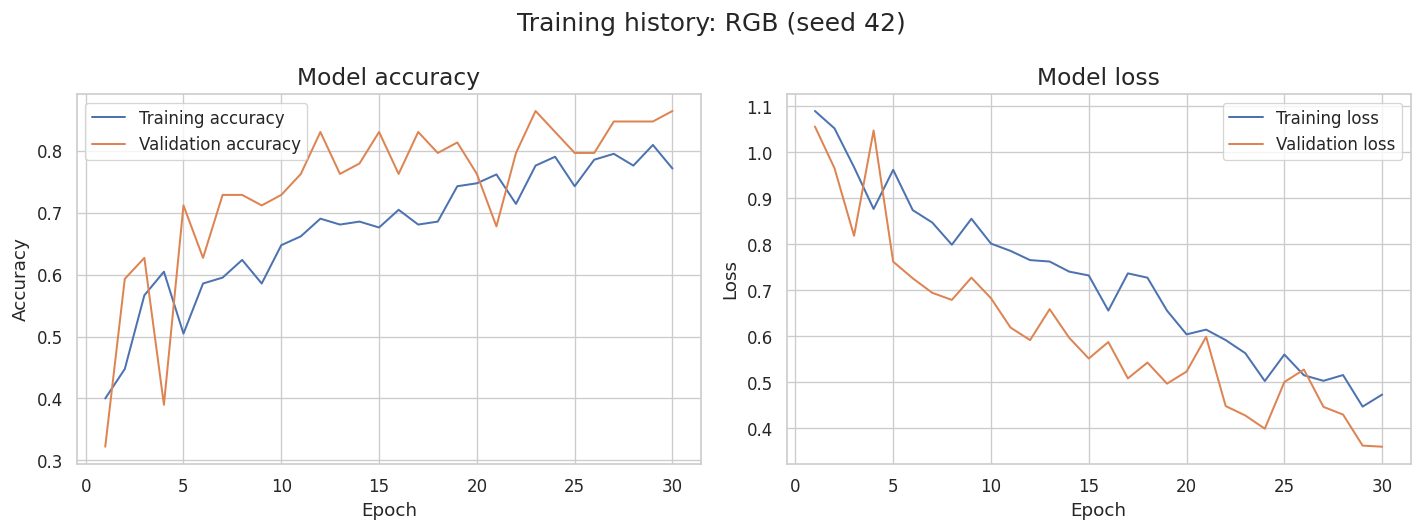

In [17]:
training_figure = visualization.plot_training_history(
    history=rgb_history,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 6.2 Inspect training history

Inspect the recorded training metrics to identify the best
validation performance and the final training and validation
metrics.

In [18]:
import pandas as pd

history_df = pd.read_csv(training_metadata["history_path"])

print("TRAINING HISTORY")
print("-" * 60)

display(history_df.head())

print("\nBEST VALIDATION PERFORMANCE")
print("-" * 60)

best_val_loss_epoch = history_df["val_loss"].idxmin()
best_val_accuracy_epoch = history_df["val_accuracy"].idxmax()

print(
    f"Lowest validation loss: "
    f"{history_df.loc[best_val_loss_epoch, 'val_loss']:.4f} "
    f"(epoch {best_val_loss_epoch + 1})"
)

print(
    f"Highest validation accuracy: "
    f"{history_df.loc[best_val_accuracy_epoch, 'val_accuracy']:.4f} "
    f"(epoch {best_val_accuracy_epoch + 1})"
)

TRAINING HISTORY
------------------------------------------------------------


,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.400000,1.090001,0.322034,1.056199,0.001
1,0.447619,1.052158,0.593220,0.965549,0.001
2,0.566667,0.967789,0.627119,0.818439,0.001
3,0.604762,0.876826,0.389830,1.047597,0.001
4,0.504762,0.961970,0.711864,0.762132,0.001



BEST VALIDATION PERFORMANCE
------------------------------------------------------------
Lowest validation loss: 0.3595 (epoch 30)
Highest validation accuracy: 0.8644 (epoch 23)


### 6.3 Verify saved training figures

Verify that the RGB training performance figures have been
saved in both PNG and PDF formats.

The figures are stored in the project output directory and
the report directory for later use in the research paper.

In [22]:
from pathlib import Path

figure_directory = Path(config.FIGURES_DIR)
report_figure_directory = Path(config.REPORT_FIGURES_DIR)

expected_files = [
    f"training_curves_{COLOR_SPACE}_seed{SEED}.png",
    f"training_curves_{COLOR_SPACE}_seed{SEED}.pdf"
]

print("RGB TRAINING FIGURES")
print("-" * 40)

for filename in expected_files:
    output_file = figure_directory / filename
    report_file = report_figure_directory / filename

    assert output_file.exists(), f"Missing output figure: {filename}"
    assert report_file.exists(), f"Missing report figure: {filename}"

    print(f"Verified: {filename}")

print("\nAll RGB training figures verified successfully.")

RGB TRAINING FIGURES
----------------------------------------
Verified: training_curves_rgb_seed42.png
Verified: training_curves_rgb_seed42.pdf

All RGB training figures verified successfully.


## 7. Test-set evaluation

Evaluate the best-performing RGB CNN using the held-out test set.

The test set is kept separate from model training and validation.
It is used only for the final evaluation of classification
performance.

The evaluation includes accuracy, macro-averaged precision,
recall and F1-score, as well as class-specific performance.

### 7.1 Evaluate the trained model

Evaluate the best RGB model using the test dataset.

The evaluation function calculates classification metrics and
generates predictions for subsequent analysis.

In [24]:
rgb_evaluation = evaluation.evaluate_model(
    model=rgb_model,
    test_dataset=test_dataset,
    color_space=COLOR_SPACE
)

print("RGB test-set evaluation completed.")

RGB test-set evaluation completed.


### 7.2 Overall classification performance

Inspect the overall classification metrics calculated on the
held-out test set.

Macro-averaged precision, recall and F1-score give equal weight
to each artistic style when calculating the overall metrics.

In [25]:
rgb_summary = rgb_evaluation["summary"]

print("RGB CLASSIFICATION PERFORMANCE")
print("-" * 45)

for metric, value in rgb_summary.items():
    print(f"{metric}: {value}")

RGB CLASSIFICATION PERFORMANCE
---------------------------------------------
color_space: rgb
seed: 42
accuracy: 0.8
macro_precision: 0.8090909090909091
macro_recall: 0.8000000000000002
macro_f1: 0.8030910609857976
test_loss: 0.4374132752418518
test_accuracy: 0.800000011920929


### 7.3 Class-specific performance

Inspect the classification report to examine how well the
model distinguishes between Monet, Picasso and Van Gogh.

Precision measures the proportion of predictions for a class
that are correct, while recall measures the proportion of
actual instances of that class that are correctly identified.

The F1-score combines precision and recall.

In [26]:
rgb_class_report = rgb_evaluation["class_report"]

display(rgb_class_report)

,precision,recall,f1-score,support
monet,0.727273,0.8,0.761905,10.0
picasso,1.000000,0.9,0.947368,10.0
vangogh,0.700000,0.7,0.700000,10.0
accuracy,0.800000,0.8,0.800000,0.8
macro avg,0.809091,0.8,0.803091,30.0
weighted avg,0.809091,0.8,0.803091,30.0


### 7.4 Confusion matrix

Generate a confusion matrix to examine the distribution of
correct and incorrect predictions across the three artistic
styles.

The diagonal represents correct classifications, while
off-diagonal values represent misclassifications.

In [27]:
rgb_confusion_matrix = rgb_evaluation["confusion_matrix"]

print("RGB CONFUSION MATRIX")
print("-" * 40)

display(
    pd.DataFrame(
        rgb_confusion_matrix,
        index=config.CLASSES,
        columns=config.CLASSES
    )
)

RGB CONFUSION MATRIX
----------------------------------------


,monet,picasso,vangogh
monet,8,0,2
picasso,0,9,1
vangogh,3,0,7


Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42.pdf


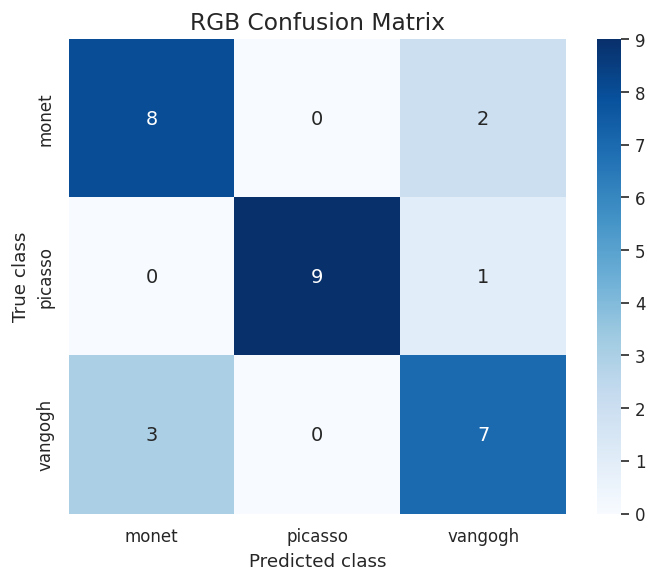

In [28]:
visualization.plot_confusion_matrix(
    confusion_matrix=rgb_confusion_matrix,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 7.6 Class-specific metric visualisation

Visualise precision, recall and F1-score for each artistic
style to identify differences in classification performance
between the classes.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_rgb_seed42.pdf


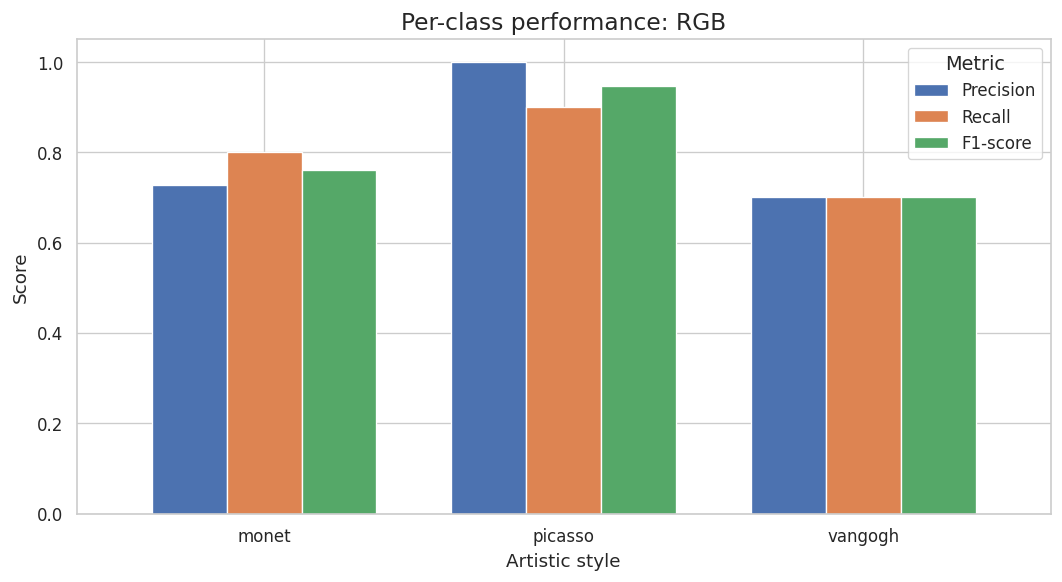

In [29]:
visualization.plot_class_metrics(
    class_report=rgb_class_report,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 7.7 Save evaluation results

Save the RGB evaluation results to the project output directory.

The saved artefacts include the overall evaluation metrics,
classification report, confusion matrix and individual predictions.
These files will support the comparison between colour-space
representations.

In [30]:
evaluation.save_evaluation_results(
    results=rgb_evaluation,
    color_space=COLOR_SPACE,
    seed=SEED
)

print("RGB evaluation results saved successfully.")

RGB evaluation results saved successfully.


In [31]:
expected_evaluation_files = [
    f"{COLOR_SPACE}_seed{SEED}_evaluation.json",
    f"{COLOR_SPACE}_seed{SEED}_classification_report.csv",
    f"{COLOR_SPACE}_seed{SEED}_confusion_matrix.csv",
    f"{COLOR_SPACE}_seed{SEED}_predictions.csv"
]

print("RGB EVALUATION ARTEFACTS")
print("-" * 45)

for filename in expected_evaluation_files:
    file_path = Path(config.METRICS_DIR) / filename

    assert file_path.exists(), f"Missing evaluation artefact: {filename}"

    print(f"Verified: {filename}")

print("\nAll RGB evaluation artefacts verified successfully.")

RGB EVALUATION ARTEFACTS
---------------------------------------------
Verified: rgb_seed42_evaluation.json
Verified: rgb_seed42_classification_report.csv
Verified: rgb_seed42_confusion_matrix.csv
Verified: rgb_seed42_predictions.csv

All RGB evaluation artefacts verified successfully.


## 8. RGB experiment results

Consolidate the RGB experiment results into a structured summary.

The summary combines training information and test-set
classification metrics, providing a single record of the
experiment for subsequent cross-colour-space comparison.

In [32]:
rgb_results = {
    "color_space": COLOR_SPACE,
    "seed": SEED,
    "epochs_completed": training_metadata["epochs_completed"],
    "best_epoch": training_metadata["best_epoch"],
    "training_time_seconds": training_metadata["training_time_seconds"],
    "parameter_count": training_metadata["parameter_count"],
    **rgb_evaluation["summary"]
}

rgb_results_df = pd.DataFrame([rgb_results])

display(rgb_results_df)

,color_space,seed,epochs_completed,best_epoch,training_time_seconds,parameter_count,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_accuracy
0,rgb,42,30,30,136.728655,110147,0.8,0.809091,0.8,0.803091,0.437413,0.8


### 8.1 Save experiment summary

Save the consolidated RGB experiment results as a CSV file.

This file will later be combined with the corresponding
summaries from the HSV and grayscale experiments.

In [33]:
rgb_summary_path = (
    Path(config.METRICS_DIR) /
    f"{COLOR_SPACE}_seed{SEED}_experiment_summary.csv"
)

rgb_results_df.to_csv(rgb_summary_path, index=False)

print("Saved:", rgb_summary_path)

Saved: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_experiment_summary.csv


### 8.2 Inspect experiment artefacts

Inspect the files generated during the RGB experiment.

These include the trained model, training history, evaluation
metrics, classification report, confusion matrix, predictions
and visualisations.

In [34]:
artifact_directories = {
    "Model": config.MODELS_DIR,
    "Metrics": config.METRICS_DIR,
    "Figures": config.FIGURES_DIR
}

for category, directory in artifact_directories.items():
    print(f"\n{category.upper()}")
    print("-" * 45)

    matching_files = sorted(
        Path(directory).glob(f"*{COLOR_SPACE}*seed{SEED}*")
    )

    for file_path in matching_files:
        if file_path.is_file():
            print(file_path.name)


MODEL
---------------------------------------------
rgb_seed42.keras

METRICS
---------------------------------------------
rgb_seed42_classification_report.csv
rgb_seed42_confusion_matrix.csv
rgb_seed42_evaluation.json
rgb_seed42_experiment_summary.csv
rgb_seed42_history.csv
rgb_seed42_predictions.csv

FIGURES
---------------------------------------------
class_metrics_rgb_seed42.pdf
class_metrics_rgb_seed42.png
confusion_matrix_rgb_seed42.pdf
confusion_matrix_rgb_seed42.png
confusion_matrix_rgb_seed42_normalized.pdf
confusion_matrix_rgb_seed42_normalized.png
training_curves_rgb_seed42.pdf
training_curves_rgb_seed42.png


### 8.3 RGB experiment record

The RGB experiment establishes the baseline against which the
HSV and grayscale experiments will be compared.

The same dataset split, CNN architecture, training configuration
and evaluation procedure will be retained across all three
colour-space representations.

The RGB results are stored independently so that they can be
combined with subsequent experiments during the final analysis.

In [35]:
assert rgb_summary_path.exists()

print("RGB EXPERIMENT COMPLETED")
print("=" * 45)
print(f"Colour space: {COLOR_SPACE.upper()}")
print(f"Random seed: {SEED}")
print(f"Best epoch: {training_metadata['best_epoch']}")
print(f"Test accuracy: {rgb_evaluation['summary']['accuracy']:.4f}")
print(f"Experiment summary: {rgb_summary_path}")

RGB EXPERIMENT COMPLETED
Colour space: RGB
Random seed: 42
Best epoch: 30
Test accuracy: 0.8000
Experiment summary: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_experiment_summary.csv
